# Le MCMC, mesuré — Metropolis–Hastings et Gibbs from-scratch

**Probas** (Fondations) — compagnon des carnets [PyMC](../PyMC/) de la série.

La série enseigne l'inférence bayésienne **à travers PyMC** (l'échantillonneur NUTS, en boîte noire). Ce carnet descend **sous le capot** : on construit un échantillonneur MCMC **from-scratch** (stdlib + numpy), on le **diagnostique** (auto-corrélation, effectif de samples indépendants, R-hat), et on **mesure** précisément là où l'approximation naïve — factoriser la posterior, la ramener à une gaussienne — **échoue**.

Le message tient en une phrase : quand la posterior a une structure qu'une forme fermée ne capture pas (corrélation, multimodalité), on ne la **calcule** plus, on la **sample** — et c'est la seule voie honnête.

- **Metropolis–Hastings** (1953 / 1970) : une chaîne de Markov dont la distribution stationnaire est la posterior ;
- **Gibbs** : cas particulier où les conditionnelles sont tirables directement ;
- **Diagnostics** : auto-corrélation → ESS, R-hat multi-chain — les instruments qu'on applique aux sorties PyMC, construits ici à la main.

**Version C#** : [carnet jumeau](Probas-MCMC-Echantillonnage-Metropolis-CSharp.ipynb).


In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1. Le principe — on ne calcule pas la posterior, on l'échantillonne

En bayésien on veut `p(θ | données) ∝ p(données | θ) · p(θ)`. Le problème : la constante de normalisation `Z = ∫ p(données|θ) p(θ) dθ` n'a **pas de forme fermée** dès que le modèle est un peu riche. PyMC ne la calcule pas non plus — NUTS **construit une chaîne de Markov** dont la loi stationnaire est la posterior, puis en tire des échantillons.

Ici on ne dispose que du **log-densité** `log p(θ)` **à une constante près** (on ignore `Z`). C'est tout ce qu'il faut à Metropolis–Hastings : l'algorithme ne compare que des **ratios** de densités, où la constante s'annule.

On définit donc deux cibles par leur log-densité, avec une **vérité connue** qu'on pourra mesurer :

- **T1 — gaussienne 2D corrélée** : moyenne `(1, -1)`, variances `1`, corrélation `ρ = 0.8`.
- **T2 — mélange bimodal 1D** : `0.5·N(2.5, 0.5²) + 0.5·N(-2.5, 0.5²)` — deux modes bien séparés, moyenne `0`, variance `6.5` (dont 6.25 vient de l'écart **entre** les modes).

In [2]:
# --- Cibles : on ne donne que le log-densite (a un facteur constant pres) ---

# T1 : gaussienne 2D correlee. Verite : mu=(1,-1), rho=0.8, variances 1 et 1.
MU   = np.array([1.0, -1.0])
RHO  = 0.8
SIG2 = np.array([1.0, 1.0])
COV  = np.array([[SIG2[0], RHO * np.sqrt(SIG2[0] * SIG2[1])],
                 [RHO * np.sqrt(SIG2[0] * SIG2[1]), SIG2[1]]])
COV_INV = np.linalg.inv(COV)

def logp_t1(theta):
    """Log-densite de la cible T1 (gaussienne 2D correlee), a constante pres."""
    d = theta - MU
    return -0.5 * d @ COV_INV @ d

# T2 : melange bimodal 1D, deux modes a +/- 2.5, sigma 0.5.
def logp_t2(x):
    """Log-densite de la cible T2 (melange de 2 gaussiennes), a constante pres.

    Log-sum-exp stable pour eviter les sous-ecoulements sur les queues."""
    x = np.asarray(x, dtype=float)
    a = -0.5 * ((x - 2.5) / 0.5) ** 2
    b = -0.5 * ((x + 2.5) / 0.5) ** 2
    m = np.maximum(a, b)
    return m + np.log(np.exp(a - m) + np.exp(b - m))

# --- Verites connues (ce qu'on va mesurer) ---
VRAI_CORR   = RHO                          # 0.8
VRAI_VAR_T2 = 0.5 * (2.5**2 + 0.5**2) + 0.5 * (2.5**2 + 0.5**2)   # = 6.5
print(f"T1 : corrélation vraie = {VRAI_CORR}, marges N(1,1) et N(-1,1)")
print(f"T2 : variance vraie    = {VRAI_VAR_T2} (moyenne 0, deux modes a +/- 2.5)")

T1 : corrélation vraie = 0.8, marges N(1,1) et N(-1,1)
T2 : variance vraie    = 6.5 (moyenne 0, deux modes a +/- 2.5)


### L'approximation naïve — ce qu'on va faire échouer

L'alternative « économique » au MCMC, quand on ne veut pas échantillonner, est d'**approcher** la posterior par une forme simple :

- **mean-field** (T1) : on **factorise** la densité 2D en produit des deux marges. Les marges sont alors correctes — mais la **corrélation tombe à zéro par construction**.
- **une gaussienne au mode** (T2) : on ne garde qu'**un** mode. La moyenne reste **sur ce mode** et la variance retombe à σ² — l'écart entre les deux modes disparaît.

Ce sont des approximations pédagogiques ; une méthode de Laplace ou variationnelle dépend de son ajustement et ne se réduit pas toujours à ces choix. Mesurons-le pour le comparer au sampleur.

In [3]:
# --- L'approximation naive : factoriser (T1) / une seule gaussienne au mode (T2) ---

def meanfield_t1(n, rng):
    """Produit des deux marges independantes : marges correctes, correlation NULLE."""
    a = rng.normal(MU[0], np.sqrt(SIG2[0]), n)
    b = rng.normal(MU[1], np.sqrt(SIG2[1]), n)
    return np.column_stack([a, b])

def naive_t2(n, rng):
    """Une seule gaussienne au mode +2.5 : un mode sur deux, moyenne au mode, variance sigma^2."""
    return rng.normal(2.5, 0.5, n)

## 2. Le moteur — Metropolis–Hastings, from-scratch

L'algorithme est minuscule. De l'état courant `x`, on **propose** un voisin `x' = x + N(0, s²)`, puis on l'**accepte** avec probabilité `min(1, p(x')/p(x))` :

```
accepter  si   log u  <=  logp(x') - logp(x)      (u ~ U(0,1))
```

`u` est tiré **avant** de savoir, donc le ratio s'évalue en log (la constante `Z` s'annule). Un `s` trop grand → presque tout est rejeté, la chaîne stagne ; trop petit → tout est accepté, la chaîne **crapahute** (échantillons quasi identiques). Le bon `s` est un **compromis mélange / gaspillage** — on le verra à l'exercice 3.

Pour la gaussienne 2D, les **conditionnelles** sont elles-mêmes gaussiennes : **Gibbs** les tire directement, sans étape d'acceptation — un cas particulier de MCMC, souvent plus rapide quand les conditionnelles sont simples.

In [4]:
def metropolis_hastings(logp, x0, n, pas, rng, burnin=0):
    """Echantillonneur Metropolis-Hastings a marche aleatoire (from scratch).

    Renvoie la trajectoire de `n` etats, apres `burnin` pas de chauffe jetes.
    """
    traj = np.empty((n, x0.size))
    x = np.asarray(x0, dtype=float)
    logp_x = float(logp(x))
    for t in range(n + burnin):
        x_new = x + rng.normal(0.0, pas, x.size)
        # Accepter si log(u) <= logp(x_new) - logp_x, u ~ U(0,1)
        if np.log(rng.random()) <= float(logp(x_new)) - logp_x:
            x = x_new
            logp_x = float(logp(x_new))
        if t >= burnin:
            traj[t - burnin] = x
    return traj

# Conditionnelles exactes de la gaussienne 2D correlee (variances = 1) :
#   t1 | t2 ~ N( mu_1 + rho*(t2 - mu_2), 1 - rho^2 )
#   t2 | t1 ~ N( mu_2 + rho*(t1 - mu_1), 1 - rho^2 )
VAR_C = 1.0 - RHO ** 2

def gibbs_t1(x0, n, rng, burnin=0):
    """Echantillonneur de Gibbs : tire chaque coordonnee de sa conditionnelle exacte."""
    traj = np.empty((n, 2))
    t1, t2 = x0
    for t in range(n + burnin):
        t1 = rng.normal(MU[0] + RHO * (t2 - MU[1]), np.sqrt(VAR_C))
        t2 = rng.normal(MU[1] + RHO * (t1 - MU[0]), np.sqrt(VAR_C))
        if t >= burnin:
            traj[t - burnin] = [t1, t2]
    return traj

## 3. Diagnostics

L'IAC et l'ESS sont ici des estimations heuristiques, tronquées au premier coefficient d'autocorrélation négatif. Le R-hat classique non scindé compare les variances intra et inter-chaînes : une valeur élevée signale une divergence, une valeur proche de 1 ne prouve pas le mélange. Les diagnostics modernes de PyMC/ArviZ utilisent notamment le découpage et la normalisation par rangs ; ils ne sont pas identiques à ces calculs pédagogiques.

In [5]:
def autocorr_time(x, max_lag=4000):
    """Temps d'auto-correlation integre (IAC) = 1 + 2*sum_{k>=1} rho_k,
    tronque au premier coefficient negatif (heuristique, sans garantie de borne)."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    var = float(x @ x)
    if var <= 0:
        return float("nan")
    iac = 1.0
    for k in range(1, min(max_lag, x.size - 1)):
        r = float(x[k:] @ x[:-k]) / var
        if r < 0:
            break
        iac += 2.0 * r
    return max(1.0, iac)

def ess(x):
    """Effectif de samples independants = N / IAC."""
    x = np.asarray(x, dtype=float).ravel()
    return x.size / autocorr_time(x)

def rhat(chains):
    """R-hat classique non scindé ; proche de 1 ne prouve pas la convergence."""
    chains = np.atleast_2d(np.asarray(chains, dtype=float))   # (n_chains, n)
    m, n = chains.shape
    if m < 2 or n < 2 or not np.isfinite(chains).all():
        return float("nan")
    within  = chains.var(axis=1, ddof=1).mean()
    between = n * chains.mean(axis=1).var(ddof=1)
    if within == 0:
        return float("inf") if between > 0 else float("nan")
    var_plus = ((n - 1) / n) * within + (1.0 / n) * between
    return float(np.sqrt(var_plus / within))

# Oracle analytique : W=4/3, variance des moyennes=8, n=4.
fixture = np.array([[-3, -1, -3, -1], [1, 3, 1, 3]])
assert np.isclose(rhat(fixture), np.sqrt(27 / 4))
assert np.isinf(rhat([[0, 0], [1, 1]]))
assert np.isnan(rhat([[0, 0], [0, 0]]))
assert np.isclose(rhat([[-1, 1, -1, 1], [-1, 1, -1, 1]]), np.sqrt(3 / 4))
print("Tests analytiques R-hat : OK")

Tests analytiques R-hat : OK


## 4. La mesure

Quatre chaînes (graines 0, 1, 7, 42) produisent chacune 10 000 échantillons après 1 000 pas de chauffe. T1 commence près de sa moyenne ; les quatre chaînes T2 partent de +2.5. Ce départ commun peut masquer une exploration incomplète ; examiner chaque chaîne est indispensable.

### Expériences fixes

Nous comparons les méthodes pour une seule corrélation, ρ = 0.8, et une seule séparation des modes, ±2.5. Aucun balayage ni point de bascule n'est mesuré ici.

In [6]:
# --- T1 : la correlation est le point de bascule ---
SEEDS = [0, 1, 7, 42]
N, BH = 10000, 1000

def run_mh(seed):
    rng = np.random.default_rng(seed)
    return metropolis_hastings(logp_t1, MU + rng.normal(0, 1, 2), N, 1.0, rng, burnin=BH)

def run_gibbs(seed):
    rng = np.random.default_rng(seed)
    return gibbs_t1(MU + rng.normal(0, 1, 2), N, rng, burnin=BH)

traj_mh  = [run_mh(s)  for s in SEEDS]
traj_gib = [run_gibbs(s) for s in SEEDS]

def corr_de(traj):
    return np.corrcoef(traj[:, 0], traj[:, 1])[0, 1]

corr_mh   = float(np.mean([corr_de(t) for t in traj_mh]))
corr_gib  = float(np.mean([corr_de(t) for t in traj_gib]))
mean_mh   = np.mean([t.mean(axis=0) for t in traj_mh], axis=0)
ess_mh    = float(np.mean([ess(t[:, 0]) for t in traj_mh]))
rhat_mh   = rhat(np.array([t[:, 0] for t in traj_mh]))

mf = meanfield_t1(N, np.random.default_rng(0))
corr_mf = float(np.corrcoef(mf[:, 0], mf[:, 1])[0, 1])

print(f"{'methode':14s} | corrélation | moyenne estimée        | ESS/ch  | R-hat")
print("-" * 66)
print(f"{ 'MCMC (MH)':14s} | {corr_mh:11.3f} | ({mean_mh[0]:.3f}, {mean_mh[1]:.3f}) | {ess_mh:7.0f} | {rhat_mh:.4f}")
print(f"{ 'Gibbs':14s} | {corr_gib:11.3f} |   (conditionnelles exactes) |     -   |   -")
print(f"{ 'mean-field':14s} | {corr_mf:11.3f} | (marges correctes)          |     -   |   -")
print(f"{ 'vérité T1':14s} | {VRAI_CORR:11.3f} | (1.000, -1.000)")
print()
print(f"Le sampleur recupere la correlation (≈ {VRAI_CORR}) ; la factorisation la remet a 0 par construction.")

methode        | corrélation | moyenne estimée        | ESS/ch  | R-hat
------------------------------------------------------------------
MCMC (MH)      |       0.801 | (1.019, -0.990) |     426 | 1.0030
Gibbs          |       0.799 |   (conditionnelles exactes) |     -   |   -
mean-field     |      -0.014 | (marges correctes)          |     -   |   -
vérité T1      |       0.800 | (1.000, -1.000)

Le sampleur recupere la correlation (≈ 0.8) ; la factorisation la remet a 0 par construction.


### Lecture — T1

Comparer la corrélation mesurée à 0.8 et celle du produit de marges indépendantes à zéro. Les écarts d'échantillonnage et les diagnostics doivent être lus dans les sorties.

In [7]:
# --- T2 : la multimodalite est le point de bascule ---
def run_mh_t2(seed):
    rng = np.random.default_rng(seed)
    # logp_t2 attend un tableau ; on emballe la cible 1D
    return metropolis_hastings(lambda v: logp_t2(np.atleast_1d(v))[0],
                                np.array([2.5]), N, 0.8, rng, burnin=BH)

traj2   = [run_mh_t2(s)[:, 0] for s in SEEDS]
all2    = np.concatenate(traj2)
var_mh2 = float(np.var(all2))
rhat2   = rhat(np.array(traj2))
frac_haut = float(np.mean(all2 > 0))     # part des echantillons pres du mode +2.5

naive2    = naive_t2(N, np.random.default_rng(0))
var_naive = float(np.var(naive2))
mean_naive = float(naive2.mean())

print(f"{'methode':14s} | variance   | moyenne     | repartition")
print("-" * 60)
print(f"{ 'MCMC (MH)':14s} | {var_mh2:10.3f} | {all2.mean():9.3f} | {frac_haut*100:5.1f} % pres du mode +2.5, R-hat {rhat2:.3f}")
print(f"{ 'naive (1 mode)':14s} | {var_naive:10.3f} | {mean_naive:9.3f} | un seul mode, au hasard")
print(f"{ 'vérité T2':14s} | {VRAI_VAR_T2:10.3f} | {0.0:9.3f} | 50 / 50 entre les deux modes")
print()
print("Moyennes par chaîne :", [round(float(t.mean()), 3) for t in traj2])
print("Comparer variance agrégée, occupation et R-hat avant de conclure au mélange.")

methode        | variance   | moyenne     | repartition
------------------------------------------------------------
MCMC (MH)      |      6.359 |     0.330 |  56.5 % pres du mode +2.5, R-hat 2.272
naive (1 mode) |      0.249 |     2.503 | un seul mode, au hasard
vérité T2      |      6.500 |     0.000 | 50 / 50 entre les deux modes

Moyennes par chaîne : [-2.337, 2.498, 2.492, -1.335]
Comparer variance agrégée, occupation et R-hat avant de conclure au mélange.


### Lecture — T2

La variance agrégée peut être proche de 6.5 même si les chaînes restent dans des modes différents. Le R-hat classique et les moyennes par chaîne exposent ce risque ; ils ne prouvent pas à eux seuls la convergence.

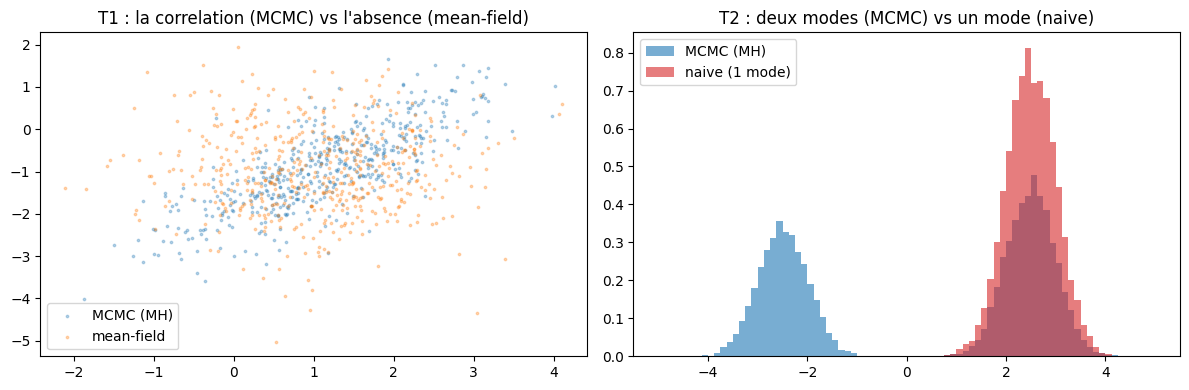

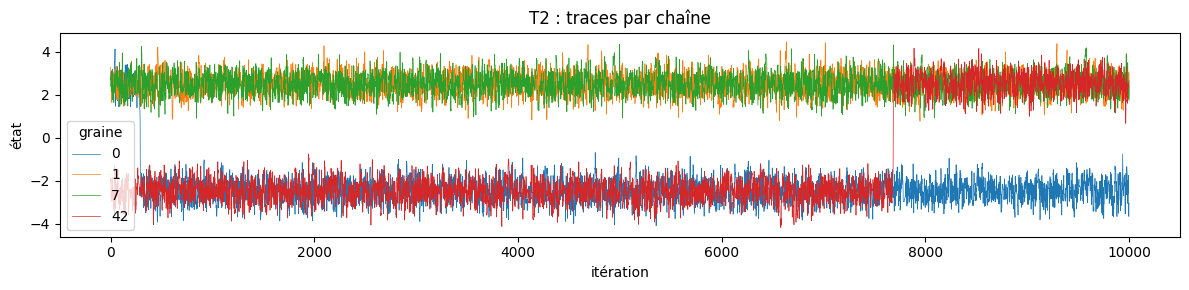

In [8]:
# --- Figures : trajectoires + densites empiriques ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# T1 : nuage 2D du MCMC vs mean-field
s0 = traj_mh[0]
ax[0].scatter(s0[::20, 0], s0[::20, 1], s=3, alpha=0.3, label="MCMC (MH)")
ax[0].scatter(mf[::20, 0], mf[::20, 1], s=3, alpha=0.3, label="mean-field")
ax[0].set_title("T1 : la correlation (MCMC) vs l'absence (mean-field)")
ax[0].legend()
# T2 : densite empirique bimodale vs naive
ax[1].hist(all2, bins=np.linspace(-5, 5, 81), density=True, alpha=0.6, label="MCMC (MH)", color="tab:blue")
ax[1].hist(naive2, bins=np.linspace(-5, 5, 81), density=True, alpha=0.6, label="naive (1 mode)", color="tab:red")
ax[1].set_title("T2 : deux modes (MCMC) vs un mode (naive)")
ax[1].legend()
fig.tight_layout()
plt.show()
fig, ax = plt.subplots(figsize=(12, 3))
for seed, chain in zip(SEEDS, traj2):
    ax.plot(chain, lw=0.5, label=str(seed))
ax.set(title="T2 : traces par chaîne", xlabel="itération", ylabel="état")
ax.legend(title="graine")
fig.tight_layout()
plt.show()

### Lecture des figures

Le nuage mean-field perd la dépendance T1. Les histogrammes T2 utilisent les mêmes bornes et sont normalisés en densité. Les traces séparées montrent si chaque chaîne explore les deux modes ; les valeurs agrégées ne suffisent pas à établir le mélange.

## 5. Exercices

Trois exercices pour prendre le moteur en main, du plus local au plus global — chaque stub s'exécute (le notebook tourne de bout en bout) ; les contrôles positifs en bas vérifient que vos implémentations retombent sur la valeur attendue :

- **l'exercice 1** isole le **cœur** de l'algorithme : la probabilité d'acceptation. C'est la seule inégalité qui fait de Metropolis–Hastings un échantillonneur correct — tout le reste (le pas, la chauffe) est de la mécanique ;
- **l'exercice 2** passe au **diagnostic** : à partir de la fonction d'auto-corrélation `ρ(t)` mesurée plus haut, en tirer le temps `τ` et l'ESS. C'est le lien direct entre « les tirages sont corrélés » et « combien de pas comptent » ;
- **l'exercice 3** remet la main dans le **réglage** : mesurer le taux d'acceptation d'une marche et le relier au pas. C'est le paramètre qu'on tourne en pratique, et le seul qu'on puisse régler **sans** connaître la cible.

In [9]:
# Exercice 1
# TODO etudiant : ecrire la probabilite d'acceptation de Metropolis-Hastings.
# Indice : on accepte avec proba min(1, exp(logp(x_new) - logp(x))) ;
#          en pratique on tire u ~ U(0,1) et on accepte si log(u) <= logp(x_new)-logp(x).
def prob_accept(x, x_new, logp):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer la probabilite d'acceptation (float)

# Controle positif : avec une x_new de même densité, la proba d'acceptation vaut 1.
assert prob_accept(np.array([0.0, 0.0]), np.array([0.0, 0.0]), logp_t1) in (None, 1.0)
print("Exercice 1 : a completer (prob_accept).")

Exercice 1 : a completer (prob_accept).


In [10]:
# Exercice 2
# TODO etudiant : a partir d'une fonction d'auto-correlation rho (tableau, rho[0]=1),
# calculer l'effectif de samples independants : ESS = N / (1 + 2*sum(rho[1:])).
def ess_from_acf(rho):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer ESS (float)

# Controle positif : pour N = 5 et rho = [1, 0.5, 0.25, 0.0, 0.0] -> 1 + 2*(0.5+0.25) = 2.5 -> ESS = 5/2.5 = 2.0
assert ess_from_acf(np.array([1.0, 0.5, 0.25, 0.0, 0.0])) in (None, 2.0)
print("Exercice 2 : a completer (ess_from_acf).")

Exercice 2 : a completer (ess_from_acf).


In [11]:
# Exercice 3
# TODO etudiant : mesurer le TAUX d'acceptation d'une marche Metropolis
# (fraction de propositions acceptees) pour une taille de pas donnee.
def taux_acceptation(logp, x0, n, pas, rng):
    # TODO etudiant
    return None  # TODO etudiant : renvoyer le taux d'acceptation (float dans [0,1])

# Controle positif : un pas huge -> toute proposition tombe ou la densite est quasi
# nulle -> rien n'est accepte -> le taux vaut EXACTEMENT 0.0 ; un pas nul repropose
# le point courant -> toujours accepte -> EXACTEMENT 1.0.
assert taux_acceptation(logp_t1, np.array([1.0, -1.0]), 500, 1e9,
                        np.random.default_rng(0)) in (None, 0.0)
assert taux_acceptation(logp_t1, np.array([1.0, -1.0]), 500, 0.0,
                        np.random.default_rng(0)) in (None, 1.0)
print("Exercice 3 : a completer (taux_acceptation).")

Exercice 3 : a completer (taux_acceptation).


## À retenir

- Une factorisation des marges perd la corrélation de T1.
- Sur T2, une variance agrégée proche de la vérité peut coexister avec des chaînes qui mélangent mal.
- Le R-hat classique non scindé et l'ESS heuristique sont des indicateurs, pas des preuves de convergence.

## En synthèse

Metropolis–Hastings compare des log-densités et Gibbs utilise les conditionnelles exactes. La convergence dépend de l'exploration réalisée, que l'on examine chaîne par chaîne.

Références : Metropolis et al. (1953), Hastings (1970), Gelman et al., *Bayesian Data Analysis*, 3e éd., §11. Voir aussi les carnets [PyMC](../PyMC/).

### De la construction à PyMC

Les principes sont communs, mais les diagnostics modernes de PyMC/ArviZ utilisent des variantes plus robustes, notamment R-hat scindé et normalisé par rangs. NUTS n'est pas la marche aléatoire de ce carnet.

### Limites

T1 est bidimensionnelle et T2 unidimensionnelle. La troncature au premier coefficient négatif est une heuristique sans garantie générale de borne sur l'ESS. Des chaînes bloquées dans le même mode peuvent afficher un R-hat proche de 1.

## Vérifiez votre compréhension

1. Pourquoi les marges correctes du mean-field ne garantissent-elles pas la bonne corrélation ?
2. Pourquoi une variance agrégée proche de 6.5 ne démontre-t-elle pas que chaque chaîne T2 a mélangé ?
3. Que peut cacher un R-hat proche de 1 lorsque toutes les chaînes partent du même mode ?

## Pour aller plus loin

- [Index de la série Probas](../README.md) : le fil complet de la série.
- Le carnet jumeau de ce dossier — `Probas-CLT-Theoreme-Central-Limite.ipynb` : l'autre manière de rendre une somme exploitable. Ici on **échantillonne** une loi sans forme closed ; là on **normalise** une somme pour la rendre gaussienne. Même exigence des deux côtés : la valeur exacte de la sortie plutôt qu'une impression.